# 05_05 Concentration Inequalities: How Fast Do Averages Stick to Their Mean?

**Learning objectives**
- State and prove **Markov**, **Chebyshev**, **Chernoff** and **Hoeffding** bounds, and know when **Bernstein** and the **KL (Chernoff) form** are sharper.
- Turn a bound into a **guaranteed sample size** (no Normal approximation, no asymptotics) and compare it with the CLT sample size.
- Use the **union bound** to make many statements hold at once (comparing $K$ models, many A/B arms).
- Build a **confidence bonus** for bandits and other online decisions from Hoeffding.

**Prerequisites:** [05_01 Law of large numbers](05_01_law_of_large_numbers.ipynb) (Chebyshev and Hoeffding sample sizes), [05_02 Central limit theorem](05_02_central_limit_theorem.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Tail probability** $P(X\ge a)$ and the **survival function** $1-F(a)$.
- **Expectation and variance** of a sum of independent variables: $E[S_n]=n\mu$, $\mathrm{Var}(S_n)=n\sigma^2$; for the mean $\mathrm{Var}(\bar X)=\sigma^2/n$.
- **Moment generating function (MGF)** $M(t)=E[e^{tX}]$; for independent variables the MGF of a sum is the product of the MGFs.
- **Kullback-Leibler divergence** between two Bernoulli laws: $\mathrm{KL}(q\|p)=q\ln\frac qp+(1-q)\ln\frac{1-q}{1-p}$.
- From 05_01: Chebyshev gives $n\ge\sigma^2/(\varepsilon^2\delta)$; the CLT gives $n\ge(z\sigma/\varepsilon)^2$ but is only approximate.

## 3. Intuition and story

The CLT says the average is *approximately* Normal. That is a statement about the **bulk**, valid for large $n$, with an unknown error. Often we need something stronger: a statement that is **true for every $n$**, with **no approximation**, even far in the tail. For example: "with probability at least 99.9 % this classifier's true accuracy is within 1 point of what we measured, **guaranteed**". Concentration inequalities give exactly that. They are cruder than the CLT (they have to cover every possible distribution of the data) but they are *safe*.

The ladder, from weakest to strongest assumption:

1. **Markov:** only that $X\ge0$ and the mean is known. A single number gives a (weak) bound.
2. **Chebyshev:** also the variance. Bound decays like $1/k^2$: polynomial.
3. **Chernoff / Hoeffding / Bernstein:** the whole MGF, or just that each $X_i$ lies in a bounded interval. The bound decays like $e^{-cn\varepsilon^2}$: **exponential** in the sample size. That is the difference between needing 50,000 examples and needing 18,000.

## 4. Formal definitions

Let $X_1,\dots,X_n$ be independent with mean $\mu$, $\bar X=\frac1n\sum X_i$, and take $\varepsilon>0$.

| Name | Assumption | Statement |
|---|---|---|
| **Markov** | $X\ge0$ | $P(X\ge a)\le E[X]/a$ |
| **Chebyshev** | variance $\sigma^2$ | $P(\lvert X-\mu\rvert\ge k\sigma)\le1/k^2$; for the mean $P(\lvert\bar X-\mu\rvert\ge\varepsilon)\le\dfrac{\sigma^2}{n\varepsilon^2}$ |
| **Chernoff** | MGF exists | $P(S_n\ge a)\le\min_{t>0}e^{-ta}M_{S_n}(t)$ |
| **Hoeffding** | $X_i\in[a_i,b_i]$ | $P(\bar X-\mu\ge\varepsilon)\le\exp\!\Big(-\dfrac{2n^2\varepsilon^2}{\sum(b_i-a_i)^2}\Big)$; for $[0,1]$: $e^{-2n\varepsilon^2}$ |
| **Bernstein** | $\lvert X_i-\mu\rvert\le b$, variance $\sigma^2$ | $P(\bar X-\mu\ge\varepsilon)\le\exp\!\Big(-\dfrac{n\varepsilon^2}{2\sigma^2+2b\varepsilon/3}\Big)$ |
| **KL (Chernoff) form** | $X_i\sim$ Bernoulli($p$) | $P(\bar X\ge q)\le e^{-n\,\mathrm{KL}(q\|p)}$ for $q>p$ |
| **Union bound** | any events | $P(\bigcup_kA_k)\le\sum_kP(A_k)$ |

Two-sided versions double the bound. **Sample size from Hoeffding** (values in $[0,1]$, error $\varepsilon$, failure probability $\delta$): $n\ge\dfrac{\ln(2/\delta)}{2\varepsilon^2}$. **For $K$ statements at once**: $n\ge\dfrac{\ln(2K/\delta)}{2\varepsilon^2}$.

## 5. Derivations

### 5.1 Markov
For $X\ge0$ and $a>0$: $E[X]\ge E[X\,\mathbf 1\{X\ge a\}]\ge a\,P(X\ge a)$. Divide by $a$. **In plain words.** If the average income is 40 000 then at most 1 person in 10 can earn 400 000 or more, because they would already use up the whole average.

### 5.2 Chebyshev from Markov
Apply Markov to the non-negative variable $(X-\mu)^2$ at level $k^2\sigma^2$: $P(|X-\mu|\ge k\sigma)=P((X-\mu)^2\ge k^2\sigma^2)\le\sigma^2/(k^2\sigma^2)=1/k^2$. For the mean, $\mathrm{Var}(\bar X)=\sigma^2/n$ gives $\sigma^2/(n\varepsilon^2)$. **In plain words.** Squaring the deviation turns "how far" into something Markov can bound; it is the reason a small variance forces values to stay near the mean.

### 5.3 Chernoff: use the MGF instead of the variance
For any $t>0$, $P(S\ge a)=P(e^{tS}\ge e^{ta})\le e^{-ta}E[e^{tS}]$ (Markov on $e^{tS}$). For independent summands $E[e^{tS}]=\prod_iM_i(t)$, and we keep the best $t$. **In plain words.** Markov is wasteful because it uses only the mean of $S$; $e^{tS}$ magnifies large values, so its mean "feels" the whole tail, and the product structure makes the bound shrink *exponentially* in $n$.

### 5.4 Hoeffding for $X_i\in[0,1]$
Hoeffding's lemma: if $Y\in[0,1]$ has mean 0 after centring, $E[e^{tY}]\le e^{t^2/8}$. Then with $Y_i=X_i-\mu$,
$$P(\bar X-\mu\ge\varepsilon)\le e^{-tn\varepsilon}\prod_iE[e^{tY_i}]\le\exp\!\big(-tn\varepsilon+nt^2/8\big).$$
The exponent is smallest at $t=4\varepsilon$, giving $\exp(-2n\varepsilon^2)$. **In plain words.** Only "each value lies between 0 and 1" is used, so the bound holds for every such distribution, which makes it safe but not tight for any particular one.

### 5.5 Sample size and the union bound
Set $2e^{-2n\varepsilon^2}=\delta$ to get $n=\ln(2/\delta)/(2\varepsilon^2)$. For $K$ estimates that must *all* be within $\varepsilon$, the union bound gives failure probability at most $2Ke^{-2n\varepsilon^2}$, so $n=\ln(2K/\delta)/(2\varepsilon^2)$: **testing 50 models together costs only $\ln 50\approx3.9$ extra in the numerator**, not 50 times the data.

### 5.6 Confidence bonus (bandits)
After $n$ pulls of an arm with rewards in $[0,1]$, the one-sided Hoeffding bound gives, with probability at least $1-\delta$, $\mu\le\bar X+\sqrt{\ln(1/\delta)/(2n)}$. This is the upper confidence bound (UCB) used to decide which arm to try next.

## 6. Properties and relationships

- **Dominance order for Bernoulli averages:** the KL form is the sharpest of the exponential bounds; Hoeffding is the same with $\mathrm{KL}(q\|p)\ge2(q-p)^2$ (Pinsker), so Hoeffding is weaker; Bernstein sits between when the variance is small.
- **Hoeffding ignores the variance**, so for rare events ($p$ near 0 or 1) it is loose; Bernstein and the KL form use $p(1-p)$ and are far better.
- **Chebyshev beats Hoeffding for moderate deviations** at small $n$ (Example 1, Question 3) but loses completely in the far tail: polynomial against exponential.
- **Relation to the CLT:** the CLT tail is $2\bar\Phi(\varepsilon\sqrt n/\sigma)\approx e^{-n\varepsilon^2/(2\sigma^2)}$; Hoeffding's exponent $2n\varepsilon^2$ is the same with the worst-case variance $\sigma^2=1/4$. So Hoeffding is "the CLT with the worst-case variance, made rigorous".
- **Sub-Gaussian variables** (bounded, Normal, Rademacher) all satisfy Hoeffding-type bounds; heavy-tailed ones (Pareto, Cauchy) do not, which is why 05_02's failure cases reappear.

## 7. 2D visuals

### 7.1 Bounds against the exact tail
Average of $n=100$ fair coin flips: $P(|\bar X-0.5|\ge\varepsilon)$ exactly (Binomial) against the Chebyshev, Hoeffding and Normal-approximation values. Every bound lies above the exact curve (that is its job); the Normal curve lies close to it but is not a guarantee.

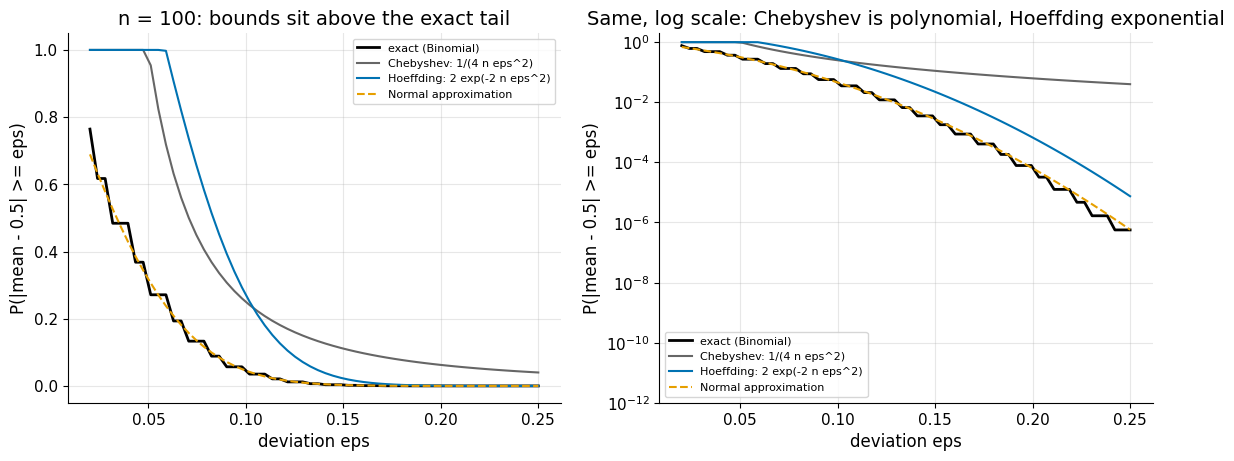

In [2]:
n = 100
eps = np.linspace(0.02, 0.25, 60)
k = np.arange(n + 1)
exact = np.array([stats.binom.pmf(k, n, 0.5)[np.abs(k / n - 0.5) >= e - 1e-12].sum() for e in eps])
cheb = np.minimum(1, 0.25 / (n * eps**2))
hoef = np.minimum(1, 2 * np.exp(-2 * n * eps**2))
norm_approx = 2 * stats.norm.sf(eps / (0.5 / np.sqrt(n)))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, logy in zip(axes, [False, True]):
    ax.plot(eps, exact, color="black", linewidth=2, label="exact (Binomial)")
    ax.plot(eps, cheb, color=NEUTRAL, label="Chebyshev: 1/(4 n eps^2)")
    ax.plot(eps, hoef, color=MAIN, label="Hoeffding: 2 exp(-2 n eps^2)")
    ax.plot(eps, norm_approx, color=SIM, linestyle="--", label="Normal approximation")
    ax.set_xlabel("deviation eps"); ax.set_ylabel("P(|mean - 0.5| >= eps)"); ax.legend(fontsize=8)
    if logy:
        ax.set_yscale("log"); ax.set_ylim(1e-12, 2); ax.set_title("Same, log scale: Chebyshev is polynomial, Hoeffding exponential")
    else:
        ax.set_title(f"n = {n}: bounds sit above the exact tail")
plt.show()
assert np.all(cheb >= exact - 1e-12) and np.all(hoef >= exact - 1e-12)

### 7.2 How many observations does a guarantee cost?
Required $n$ for failure probability $\delta=0.05$ against the error $\varepsilon$ (values in $[0,1]$, worst case $\sigma^2=1/4$). At $\varepsilon=0.01$ Chebyshev needs about 2.7 times as many as Hoeffding, and the CLT (not a guarantee) about half as many as Hoeffding.

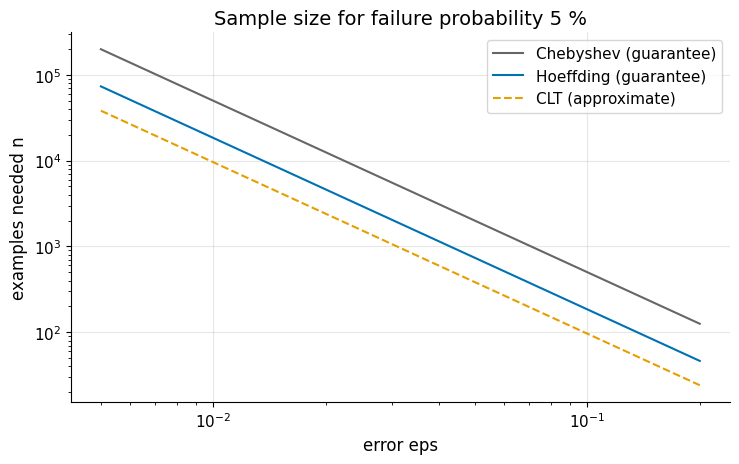

{'Chebyshev': 50392, 'Hoeffding': 18589, 'CLT': 9679} (at the grid point nearest eps = 0.01)


In [3]:
eps_grid = np.logspace(-2.3, -0.7, 60)
delta = 0.05
n_cheb = 0.25 / (eps_grid**2 * delta)
n_hoef = np.log(2 / delta) / (2 * eps_grid**2)
n_norm = (stats.norm.isf(delta / 2) * 0.5 / eps_grid) ** 2
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.loglog(eps_grid, n_cheb, color=NEUTRAL, label="Chebyshev (guarantee)")
ax.loglog(eps_grid, n_hoef, color=MAIN, label="Hoeffding (guarantee)")
ax.loglog(eps_grid, n_norm, color=SIM, linestyle="--", label="CLT (approximate)")
ax.set_xlabel("error eps"); ax.set_ylabel("examples needed n"); ax.set_title("Sample size for failure probability 5 %"); ax.legend()
plt.show()
print({m: int(np.ceil(v[np.argmin(np.abs(eps_grid - 0.01))])) for m, v in [("Chebyshev", n_cheb), ("Hoeffding", n_hoef), ("CLT", n_norm)]}, "(at the grid point nearest eps = 0.01)")

### 7.3 Markov and Chebyshev are tight only for special laws
For an Exponential variable with mean 1, the true tail is $e^{-a}$; Markov says $1/a$ and Chebyshev (centred, $\sigma=1$) says $1/(a-1)^2$. Both hold, both are very loose. They are *attained* only by two- and three-point distributions, so they cannot be improved without more assumptions.

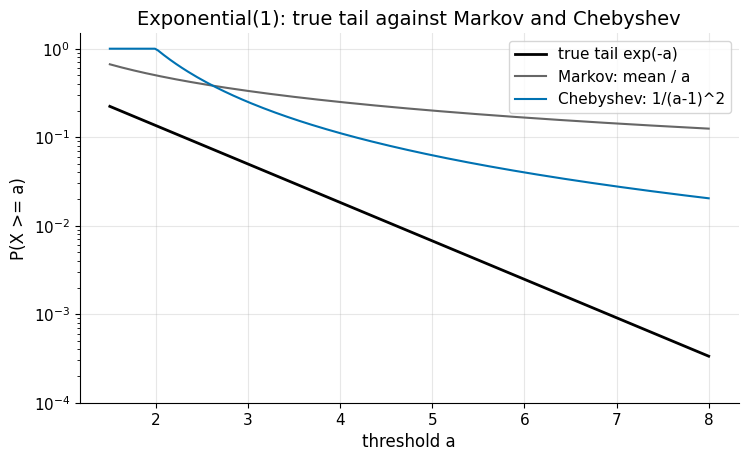

In [4]:
a = np.linspace(1.5, 8, 200)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.semilogy(a, np.exp(-a), color="black", linewidth=2, label="true tail exp(-a)")
ax.semilogy(a, np.minimum(1, 1 / a), color=NEUTRAL, label="Markov: mean / a")
ax.semilogy(a, np.minimum(1, 1 / (a - 1) ** 2), color=MAIN, label="Chebyshev: 1/(a-1)^2")
ax.set_xlabel("threshold a"); ax.set_ylabel("P(X >= a)"); ax.set_ylim(1e-4, 1.5); ax.set_title("Exponential(1): true tail against Markov and Chebyshev"); ax.legend()
plt.show()

### 7.4 Rare events: Hoeffding is loose, Bernstein and the KL form are tight
Count of failures among $n=1000$ requests with failure probability $p=0.01$: $P(\bar X\ge q)$ for $q$ from 0.015 to 0.05. Hoeffding ignores that the variance is tiny; Bernstein and the KL bound use it.

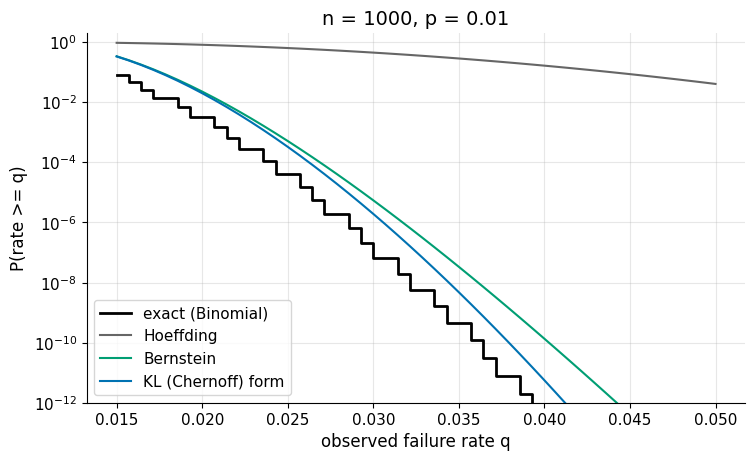

In [5]:
n, p = 1000, 0.01
q = np.linspace(0.015, 0.05, 50)
exact_tail = stats.binom.sf(np.ceil(q * n) - 1, n, p)
hoeff = np.exp(-2 * n * (q - p) ** 2)
bern = np.exp(-n * (q - p) ** 2 / (2 * p * (1 - p) + 2 * (1 - p) * (q - p) / 3))
kl = q * np.log(q / p) + (1 - q) * np.log((1 - q) / (1 - p))
chern = np.exp(-n * kl)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.semilogy(q, exact_tail, color="black", linewidth=2, drawstyle="steps-post", label="exact (Binomial)")
ax.semilogy(q, hoeff, color=NEUTRAL, label="Hoeffding")
ax.semilogy(q, bern, color=COLORS[2], label="Bernstein")
ax.semilogy(q, chern, color=MAIN, label="KL (Chernoff) form")
ax.set_xlabel("observed failure rate q"); ax.set_ylabel("P(rate >= q)"); ax.set_ylim(1e-12, 2); ax.legend(); ax.set_title("n = 1000, p = 0.01")
plt.show()
assert np.all(chern >= exact_tail - 1e-12) and np.all(bern >= exact_tail - 1e-12) and np.all(hoeff >= exact_tail - 1e-12)

## 8. 3D visuals

### 8.1 Static: the Hoeffding bound over $(n,\varepsilon)$
$\log_{10}$ of $2e^{-2n\varepsilon^2}$. The bound is useless (near 1, flat) in the corner of small $n$ and small $\varepsilon$ and then collapses exponentially along the diagonal $n\varepsilon^2\approx$ constant.

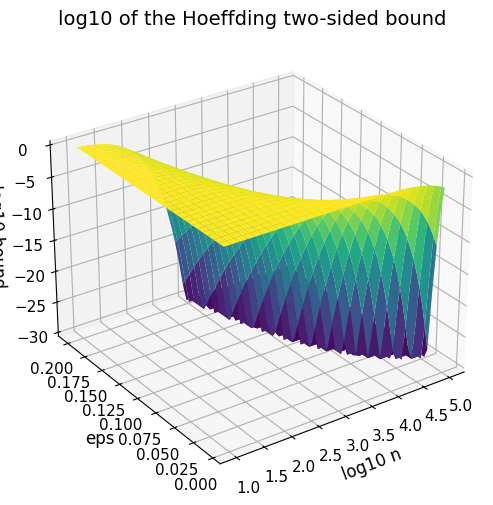

In [6]:
n_axis = np.logspace(1, 5, 60)
e_axis = np.linspace(0.005, 0.2, 60)
Z = np.log10(np.maximum(np.minimum(1, 2 * np.exp(-2 * n_axis[None, :] * e_axis[:, None] ** 2)), 1e-30))
Ng, Eg = np.meshgrid(np.log10(n_axis), e_axis)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Ng, Eg, Z, cmap="viridis", edgecolor="none")
ax.set_title("log10 of the Hoeffding two-sided bound")
ax.set_xlabel("log10 n"); ax.set_ylabel("eps"); ax.set_zlabel("log10 bound")
ax.view_init(elev=28, azim=-125)
plt.show()

### 8.2 Interactive Plotly version of 8.1
Hover to read the bound at any $(n,\varepsilon)$.

In [7]:
fig = go.Figure(go.Surface(x=n_axis, y=e_axis, z=Z, colorscale="Viridis"))
fig.update_layout(title="log10 Hoeffding bound", width=750, height=550,
                  scene=dict(xaxis_title="n", yaxis_title="eps", zaxis_title="log10 bound", xaxis_type="log"))
fig.show()

### 8.3 Static: how loose is Hoeffding? Ratio to the exact tail
Height is $\log_{10}$(Hoeffding bound / exact tail) for the average of $n$ fair coin flips. It grows with $n$ and $\varepsilon$: the bound is about right in the exponent but loses a polynomial factor, which is a large ratio far in the tail.

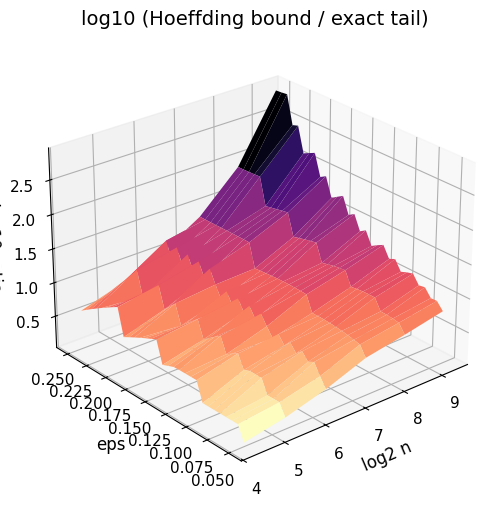

In [8]:
ns = np.array([20, 40, 80, 160, 320, 640])
es = np.linspace(0.05, 0.25, 30)
R = np.zeros((len(es), len(ns)))
for j, nn in enumerate(ns):
    kk = np.arange(nn + 1); pm = stats.binom.pmf(kk, nn, 0.5)
    for i, e in enumerate(es):
        ex = pm[np.abs(kk / nn - 0.5) >= e - 1e-12].sum()
        R[i, j] = np.log10(min(1, 2 * np.exp(-2 * nn * e * e)) / max(ex, 1e-300))
Xg, Yg = np.meshgrid(np.log2(ns), es)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Xg, Yg, R, cmap="magma_r", edgecolor="none")
ax.set_title("log10 (Hoeffding bound / exact tail)"); ax.set_xlabel("log2 n"); ax.set_ylabel("eps"); ax.set_zlabel("log10 ratio")
ax.view_init(elev=26, azim=-130)
plt.show()
assert R.min() > -1e-9

## 9. Simulation vs theory

### 9.1 Hoeffding holds for every bounded law
Five very different distributions on $[0,1]$ (all with $n=100$ observations, $\varepsilon=0.1$): Bernoulli(0.5), two-point at 0 and 1 with $p=0.05$, Uniform, Beta(0.3,0.3) (U-shaped) and a constant. For each, the simulated tail $P(|\bar X-\mu|\ge0.1)$ must stay below $2e^{-2n\varepsilon^2}=2e^{-2}=0.271$ for every law; the largest simulated tail (the fair coin, 0.035) is about 8 times below the bound, and the others are far below it.

In [9]:
n, eps_ = 100, 0.1
laws = {
    "Bernoulli(0.5)": (lambda size: rng.binomial(1, 0.5, size), 0.5),
    "Bernoulli(0.05)": (lambda size: rng.binomial(1, 0.05, size), 0.05),
    "Uniform(0,1)": (lambda size: rng.uniform(size=size), 0.5),
    "Beta(0.3,0.3)": (lambda size: rng.beta(0.3, 0.3, size), 0.5),
    "constant 0.7": (lambda size: np.full(size, 0.7), 0.7),
}
bound = 2 * np.exp(-2 * n * eps_**2)
rows = []
for name, (draw, mu) in laws.items():
    means = draw((100_000, n)).mean(axis=1)
    rows.append({"law": name, "simulated P(|mean-mu| >= 0.1)": np.mean(np.abs(means - mu) >= eps_), "Hoeffding bound": bound})
sim_table = pd.DataFrame(rows)
print(sim_table.round(4).to_string(index=False))
assert (sim_table["simulated P(|mean-mu| >= 0.1)"] <= sim_table["Hoeffding bound"]).all()

            law  simulated P(|mean-mu| >= 0.1)  Hoeffding bound
 Bernoulli(0.5)                         0.0349           0.2707
Bernoulli(0.05)                         0.0000           0.2707
   Uniform(0,1)                         0.0006           0.2707
  Beta(0.3,0.3)                         0.0115           0.2707
   constant 0.7                         0.0000           0.2707


### 9.2 The KL bound is the best exponential rate for Bernoulli
For $p=0.3$ and $q=0.4$, the Binomial tail satisfies $P(\bar X\ge q)\approx e^{-n\,\mathrm{KL}(q\|p)}$ up to a polynomial factor: the **rate** $-\frac1n\ln P$ converges to $\mathrm{KL}(q\|p)$ as $n$ grows, while Hoeffding's rate $2(q-p)^2$ is smaller.

In [10]:
p_, q_ = 0.3, 0.4
kl_rate = q_ * np.log(q_ / p_) + (1 - q_) * np.log((1 - q_) / (1 - p_))
rows = []
for nn in [50, 200, 1000, 5000, 20000]:
    tail = stats.binom.logsf(np.ceil(q_ * nn) - 1, nn, p_)
    rows.append({"n": nn, "-ln P / n": -tail / nn, "KL(q||p)": kl_rate, "Hoeffding rate 2(q-p)^2": 2 * (q_ - p_) ** 2})
rate = pd.DataFrame(rows)
print(rate.round(4).to_string(index=False))
assert abs(rate["-ln P / n"].iloc[-1] - kl_rate) < 0.003

    n  -ln P / n  KL(q||p)  Hoeffding rate 2(q-p)^2
   50     0.0493    0.0226                     0.02
  200     0.0321    0.0226                     0.02
 1000     0.0252    0.0226                     0.02
 5000     0.0233    0.0226                     0.02
20000     0.0228    0.0226                     0.02


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("exact Binomial tail P(X >= 20), n=1000, p=0.01:", stats.binom.sf(19, 1000, 0.01).round(5))
print("Markov, Chebyshev:", 10 / 20, round(9.9 / 100, 3))
print("Hoeffding sample size, eps 0.01, delta 0.05:", int(np.ceil(np.log(2 / 0.05) / (2 * 0.01**2))))
print("Hoeffding sample size for K = 50 models:", int(np.ceil(np.log(2 * 50 / 0.05) / (2 * 0.01**2))))
print("KL divergence of Bernoulli (stats.entropy(pk, qk)):", round(stats.entropy([0.02, 0.98], [0.01, 0.99]), 5), "= q ln(q/p) + (1-q) ln((1-q)/(1-p))")
print("log tail of a Binomial without underflow: stats.binom.logsf(k, n, p) ->", round(stats.binom.logsf(399, 1000, 0.3), 3))
print("Normal quantile for the CLT size: stats.norm.isf(0.025) ->", round(stats.norm.isf(0.025), 4))
print("exact two-sided binomial size search: smallest n with P(|mean - 0.5| > 0.01) <= 0.05")

exact Binomial tail P(X >= 20), n=1000, p=0.01: 0.00329
Markov, Chebyshev: 0.5 0.099
Hoeffding sample size, eps 0.01, delta 0.05: 18445
Hoeffding sample size for K = 50 models: 38005
KL divergence of Bernoulli (stats.entropy(pk, qk)): 0.00391 = q ln(q/p) + (1-q) ln((1-q)/(1-p))
log tail of a Binomial without underflow: stats.binom.logsf(k, n, p) -> -25.229
Normal quantile for the CLT size: stats.norm.isf(0.025) -> 1.96
exact two-sided binomial size search: smallest n with P(|mean - 0.5| > 0.01) <= 0.05


In [12]:
def worst_error(nn, eps=0.01):
    kk = np.arange(nn + 1)
    return stats.binom.pmf(kk, nn, 0.5)[np.abs(kk / nn - 0.5) > eps + 1e-12].sum()
lo_n, hi_n = 5_000, 20_000                  # bisection on the (almost monotone) error probability
while hi_n - lo_n > 1:
    mid = (lo_n + hi_n) // 2
    lo_n, hi_n = (mid, hi_n) if worst_error(mid) > 0.05 else (lo_n, mid)
print("smallest n found:", hi_n, "with error probability", round(worst_error(hi_n), 4))
exact_n = hi_n

smallest n found:

 9555 with error probability 0.0495


## 11. Real-world worked examples

---
### Example 1 (main): how many test examples does a guaranteed accuracy estimate need?

**Scenario.** A team has trained a spam classifier and will report its accuracy on a held-out set of labelled emails. They want a statement that is **guaranteed, with no Normal approximation**: the reported accuracy is within $\pm1$ point of the true accuracy with probability at least 95 %, whatever the true accuracy is. Each email is correctly classified (1) or not (0), so values lie in $[0,1]$ with variance at most $1/4$.

**Questions**
1. How many labelled emails are needed according to **Chebyshev**, **Hoeffding** and the **CLT**? What is the exact answer?
2. The team compares **$K=50$** candidate models and wants all 50 accuracy estimates to be within $\pm1$ point simultaneously. How many examples now?
3. With only **$n=2{,}000$** examples, bound the probability that the accuracy estimate is off by 2 points or more.

### 11.1 By hand
**Q1.** Worst case $\sigma^2=\tfrac14$, $\varepsilon=0.01$, $\delta=0.05$.
- Chebyshev: $n\ge\dfrac{\sigma^2}{\varepsilon^2\delta}=\dfrac{0.25}{0.0001\times0.05}=50{,}000$.
- Hoeffding: $n\ge\dfrac{\ln(2/\delta)}{2\varepsilon^2}=\dfrac{\ln40}{0.0002}=\dfrac{3.689}{0.0002}=18{,}445$ (rounded up).
- CLT: $n\ge(z\sigma/\varepsilon)^2=(1.96\times0.5/0.01)^2=9{,}604$.

**Q2.** Union bound: $n\ge\dfrac{\ln(2K/\delta)}{2\varepsilon^2}=\dfrac{\ln2000}{0.0002}=\dfrac{7.601}{0.0002}=38{,}005$: about twice the single-model number, not 50 times.

**Q3.** $n=2000$, $\varepsilon=0.02$: Hoeffding $2e^{-2\cdot2000\cdot0.0004}=2e^{-1.6}=0.404$; Chebyshev $\dfrac{0.25}{2000\times0.0004}=0.3125$; CLT $2\bar\Phi\big(0.02/(0.5/\sqrt{2000})\big)=2\bar\Phi(1.789)=0.074$.

In [13]:
eps_, delta_ = 0.01, 0.05
n_cheb = int(np.ceil(0.25 / (eps_**2 * delta_)))
n_hoef = int(np.ceil(np.log(2 / delta_) / (2 * eps_**2)))
n_clt = int(np.ceil((stats.norm.isf(delta_ / 2) * 0.5 / eps_) ** 2))
print(f"Q1: Chebyshev {n_cheb:,} | Hoeffding {n_hoef:,} | CLT {n_clt:,} | exact worst case (Binomial, p = 0.5) {exact_n:,}")
n_union = int(np.ceil(np.log(2 * 50 / delta_) / (2 * eps_**2)))
print(f"Q2: K = 50 models, Hoeffding + union bound: {n_union:,} examples ({n_union / n_hoef:.2f} times the single-model size)")
n_small, e_small = 2000, 0.02
kk = np.arange(n_small + 1)
exact_small = stats.binom.pmf(kk, n_small, 0.5)[np.abs(kk / n_small - 0.5) >= e_small - 1e-12].sum()
b_cheb, b_hoef = 0.25 / (n_small * e_small**2), 2 * np.exp(-2 * n_small * e_small**2)
b_norm = 2 * stats.norm.sf(e_small / (0.5 / np.sqrt(n_small)))
print(f"Q3: Chebyshev {b_cheb:.4f} | Hoeffding {b_hoef:.4f} | CLT {b_norm:.4f} | exact (worst case p = 0.5) {exact_small:.4f}")

Q1: Chebyshev 50,000 | Hoeffding 18,445 | CLT 9,604 | exact worst case (Binomial, p = 0.5) 9,555
Q2: K = 50 models, Hoeffding + union bound: 38,005 examples (2.06 times the single-model size)
Q3: Chebyshev 0.3125 | Hoeffding 0.4038 | CLT 0.0736 | exact (worst case p = 0.5) 0.0773


### 11.2 In code with `scipy`, and the asserts

In [14]:
assert (n_cheb, n_hoef, n_clt, n_union) == (50000, 18445, 9604, 38005)
assert exact_n <= n_clt <= n_hoef <= n_cheb and n_clt - exact_n < 100          # the exact size is a hair below the CLT's and far below Hoeffding's
assert abs(b_hoef - 0.4038) < 1e-4 and abs(b_cheb - 0.3125) < 1e-9 and abs(b_norm - 0.0736) < 1e-3
assert b_cheb < b_hoef                                           # at moderate deviation and small n Chebyshev is tighter than Hoeffding
assert exact_small <= b_norm * 1.15 and exact_small <= b_cheb and exact_small <= b_hoef
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Simulate many test sets: (a) with $n=2000$ the fraction with error $\ge2$ points; (b) with the guaranteed sizes, the actual failure rate (it should be well below 5 % for Hoeffding and Chebyshev, about 5 % for the CLT and exact sizes).

In [15]:
sim_rng = np.random.default_rng(11)
reps = 400_000
err_2000 = np.abs(sim_rng.binomial(2000, 0.5, reps) / 2000 - 0.5)
print(f"(a) n = 2000: P(error >= 0.02): simulated {np.mean(err_2000 >= 0.02 - 1e-12):.4f} | exact {exact_small:.4f}")
rows = []
for name, nn in [("CLT size", n_clt), ("exact size", exact_n), ("Hoeffding size", n_hoef), ("Chebyshev size", n_cheb)]:
    fails = np.mean(np.abs(sim_rng.binomial(nn, 0.5, reps) / nn - 0.5) > 0.01 + 1e-12)
    rows.append({"design": name, "n": nn, "simulated failure probability": fails})
design = pd.DataFrame(rows)
print(design.round(4).to_string(index=False))
assert abs(np.mean(err_2000 >= 0.02 - 1e-12) - exact_small) < 0.004
assert design.iloc[0]["simulated failure probability"] < 0.06 and design.iloc[2]["simulated failure probability"] < 0.01

(a) n = 2000: P(error >= 0.02): simulated 0.0783 | exact 0.0773


        design     n  simulated failure probability
      CLT size  9604                         0.0492
    exact size  9555                         0.0502
Hoeffding size 18445                         0.0066
Chebyshev size 50000                         0.0000

### 11.4 Plots with the regions shaded

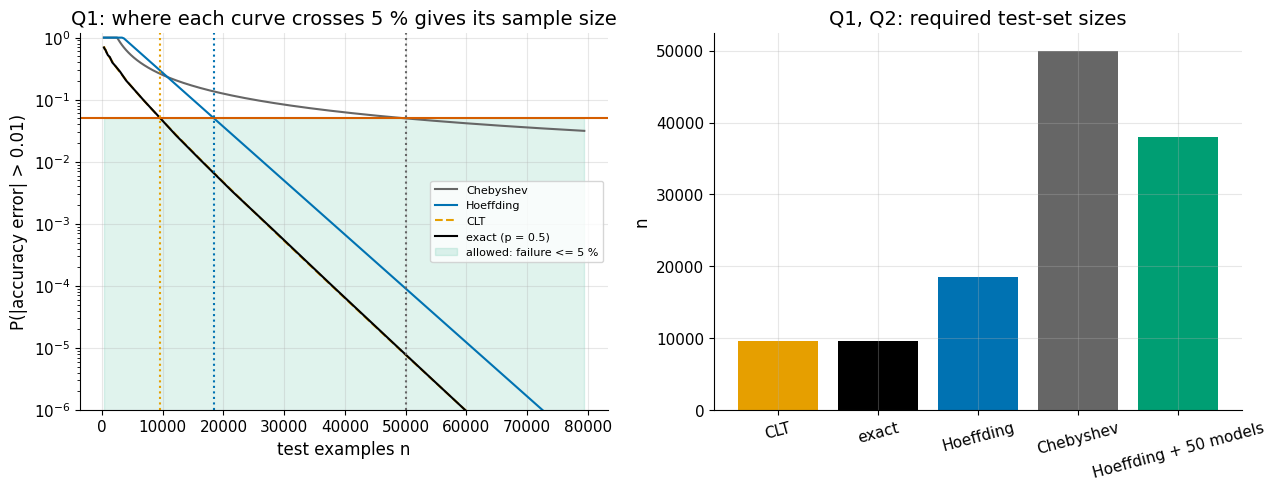

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))
ns_ = np.unique(np.logspace(2.5, 4.9, 60).astype(int))
tail_exact = np.array([worst_error(nn) for nn in ns_[::3]])
axes[0].semilogy(ns_, np.minimum(1, 0.25 / (ns_ * 0.01**2)), color=NEUTRAL, label="Chebyshev")
axes[0].semilogy(ns_, np.minimum(1, 2 * np.exp(-2 * ns_ * 0.01**2)), color=MAIN, label="Hoeffding")
axes[0].semilogy(ns_, 2 * stats.norm.sf(0.01 * np.sqrt(ns_) / 0.5), color=SIM, linestyle="--", label="CLT")
axes[0].semilogy(ns_[::3], tail_exact, color="black", label="exact (p = 0.5)")
axes[0].axhline(0.05, color=HIGHLIGHT); axes[0].fill_between(ns_, 1e-8, 0.05, color=COLORS[2], alpha=0.12, label="allowed: failure <= 5 %")
for nn, c in [(n_clt, SIM), (n_hoef, MAIN), (n_cheb, NEUTRAL)]:
    axes[0].axvline(nn, color=c, linestyle=":")
axes[0].set_ylim(1e-6, 1.2); axes[0].set_xlabel("test examples n"); axes[0].set_ylabel("P(|accuracy error| > 0.01)")
axes[0].set_title("Q1: where each curve crosses 5 % gives its sample size"); axes[0].legend(fontsize=8)
axes[1].bar(["CLT", "exact", "Hoeffding", "Chebyshev", "Hoeffding + 50 models"], [n_clt, exact_n, n_hoef, n_cheb, n_union], color=[SIM, "black", MAIN, NEUTRAL, COLORS[2]])
axes[1].set_title("Q1, Q2: required test-set sizes"); axes[1].set_ylabel("n")
axes[1].tick_params(axis="x", labelrotation=15)
plt.show()

### 11.5 Interpretation and decision
- **Cost of a guarantee.** A fully guaranteed answer costs **18,445** emails (Hoeffding) against **9,604** for the CLT and **9,555** exactly: the guarantee is paid for with roughly *twice* the data. Chebyshev's 50,000 is five times too many: use the exponential bound whenever values are bounded.
- **Many models at once.** Checking all 50 candidate models needs **38,005** examples, only twice the single-model size, because the union bound adds just $\ln50$ to the logarithm.
- **Small test sets.** With 2,000 emails the bounds only promise "within 2 points with probability about 60 to 70 %" (Chebyshev 0.3125 and Hoeffding 0.404 for the *failure* probability), while the exact failure probability is 0.077: a 2-point claim at 2,000 examples is fine in practice but not guaranteed.
- **Decision.** Label **about 10,000 emails** if an approximate 95 % statement is enough; label **about 18,500** (or 38,000 for 50 models) if the claim goes into a contract or safety case and must hold for sure.

---
### Example 2: rare failures in a request stream (which bound to trust)

**Scenario.** A service handles $n=1{,}000$ requests per minute and each fails independently with probability $p=0.01$ (mean 10 failures). An alarm fires at **20 or more** failures in a minute. How likely is a false alarm, and which bound would you quote?

### 11.6 By hand, in code and by simulation
**By hand.** Markov: $P(X\ge20)\le10/20=0.5$. Chebyshev ($\sigma^2=np(1-p)=9.9$): $P(|X-10|\ge10)\le9.9/100=0.099$. Chernoff/KL with $q=0.02$: $\mathrm{KL}=0.02\ln2+0.98\ln\frac{0.98}{0.99}=0.01386-0.009949=0.003916$ per request, so $e^{-1000\times0.003916}\approx0.0199$. Bernstein ($\varepsilon=0.01$, $\sigma^2=0.0099$, $b=0.99$): $\exp\!\big(-1000\cdot10^{-4}/(0.0198+0.0066)\big)\approx0.0226$. Hoeffding: $e^{-2\cdot1000\cdot10^{-4}}=e^{-0.2}=0.819$.

exact 0.00329 | simulated 0.00331
{'Markov': 0.5, 'Chebyshev': 0.099, 'Hoeffding': np.float64(0.8187), 'Bernstein': np.float64(0.0226), 'KL (Chernoff)': np.float64(0.02)}


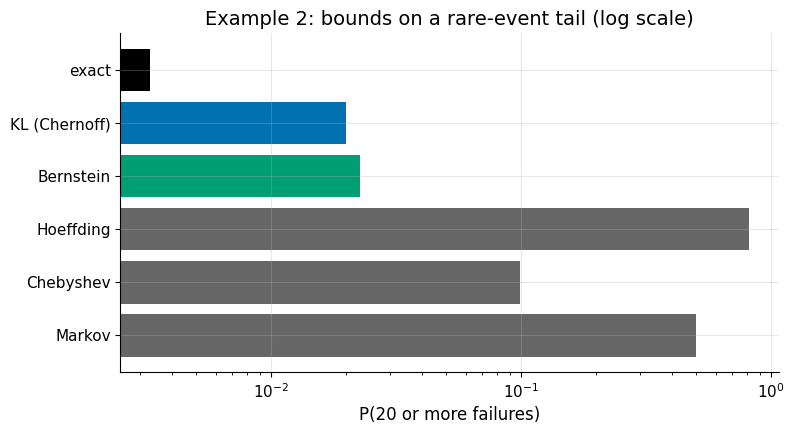

In [17]:
n, p = 1000, 0.01
exact_p = stats.binom.sf(19, n, p)
kl_ = 0.02 * np.log(0.02 / 0.01) + 0.98 * np.log(0.98 / 0.99)
bounds = {"Markov": 10 / 20, "Chebyshev": 9.9 / 100, "Hoeffding": np.exp(-2 * n * 0.01**2),
          "Bernstein": np.exp(-n * 0.01**2 / (2 * 0.0099 + 2 * 0.99 * 0.01 / 3)), "KL (Chernoff)": np.exp(-n * kl_)}
sim_p = np.mean(np.random.default_rng(21).binomial(n, p, 2_000_000) >= 20)
print(f"exact {exact_p:.5f} | simulated {sim_p:.5f}")
print({k: round(v, 4) for k, v in bounds.items()})
assert all(v >= exact_p for v in bounds.values()) and abs(sim_p - exact_p) < 0.0004
assert bounds["KL (Chernoff)"] < bounds["Bernstein"] < bounds["Chebyshev"] < bounds["Markov"] < bounds["Hoeffding"] + 0.5
fig, ax = plt.subplots(figsize=(8.5, 4.4))
names = list(bounds) + ["exact"]
vals = list(bounds.values()) + [exact_p]
ax.barh(names, vals, color=[NEUTRAL, NEUTRAL, NEUTRAL, COLORS[2], MAIN, "black"])
ax.set_xscale("log"); ax.set_xlabel("P(20 or more failures)"); ax.set_title("Example 2: bounds on a rare-event tail (log scale)")
plt.show()

**Decision.** The true false-alarm probability is about **0.33 %**. The best guarantee, the KL form, says "at most 2 %" (6 times too high but the right order); Hoeffding says 82 %, a useless statement, because it ignores that failures are rare. **For rare events always use Bernstein or the KL form, never plain Hoeffding.** For alarm design, set the threshold from the exact Binomial, and keep the KL bound as the guaranteed upper limit.

---
### Example 3: a confidence bonus for choosing between two ads (bandits)

**Scenario.** Ad A has been shown 100 times and clicked 62 times (rate 0.62). Ad B has been shown 20 times with 14 clicks (rate 0.70). Which should be shown next if we want to be 95 % sure not to *under-estimate* an ad's true click rate?

### 11.7 By hand, in code and by simulation
**By hand.** One-sided Hoeffding bonus $\sqrt{\ln(1/\delta)/(2n)}$ with $\delta=0.05$, $\ln20=2.996$: ad A $\sqrt{2.996/200}=0.1224$, so upper bound $0.742$; ad B $\sqrt{2.996/40}=0.2737$, so $0.974$. Ad B has a **larger upper confidence bound** and is shown next (it is uncertain, so it deserves more exploration).

{'A': np.float64(0.7424), 'B': np.float64(0.9737)} -> next ad: B


true rate  0.1     0.5     0.9
n                             
20         1.0  0.9940  0.9995
100        1.0  0.9941  0.9999
1000       1.0  0.9926  0.9999


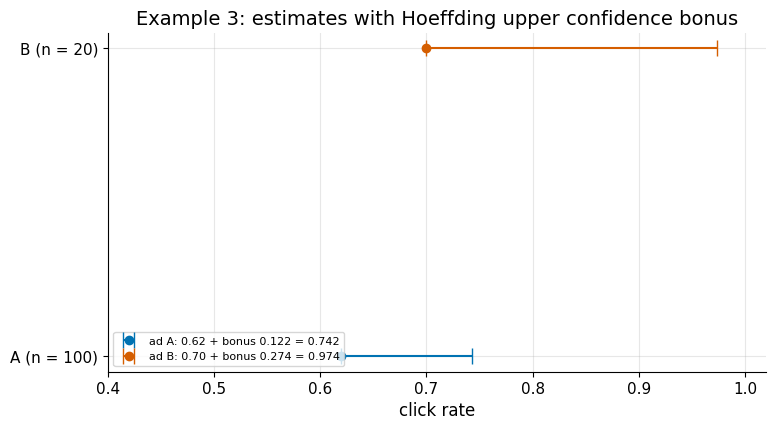

In [18]:
delta = 0.05
clicks, shows = {"A": 62, "B": 14}, {"A": 100, "B": 20}
ucb = {a: clicks[a] / shows[a] + np.sqrt(np.log(1 / delta) / (2 * shows[a])) for a in clicks}
print({a: round(v, 4) for a, v in ucb.items()}, "-> next ad:", max(ucb, key=ucb.get))
assert abs(ucb["A"] - 0.7424) < 5e-4 and abs(ucb["B"] - 0.9737) < 5e-4 and max(ucb, key=ucb.get) == "B"
# coverage of the bonus: how often does the true rate stay below the upper bound?
cov_rng = np.random.default_rng(5)
rows = []
for n_ in [20, 100, 1000]:
    for true_p in [0.1, 0.5, 0.9]:
        phat = cov_rng.binomial(n_, true_p, 200_000) / n_
        rows.append({"n": n_, "true rate": true_p, "P(true <= upper bound)": np.mean(true_p <= phat + np.sqrt(np.log(1 / delta) / (2 * n_)))})
cover = pd.DataFrame(rows)
print(cover.round(4).pivot(index="n", columns="true rate", values="P(true <= upper bound)").to_string())
assert cover["P(true <= upper bound)"].min() >= 0.95
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for i, a in enumerate(["A", "B"]):
    phat_ = clicks[a] / shows[a]; bonus = ucb[a] - phat_
    ax.errorbar(phat_, i, xerr=[[0], [bonus]], fmt="o", color=[MAIN, HIGHLIGHT][i], capsize=6, label=f"ad {a}: {phat_:.2f} + bonus {bonus:.3f} = {ucb[a]:.3f}")
ax.set_yticks([0, 1]); ax.set_yticklabels(["A (n = 100)", "B (n = 20)"]); ax.set_xlabel("click rate"); ax.set_xlim(0.4, 1.02); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Example 3: estimates with Hoeffding upper confidence bonus")
plt.show()

**Decision.** Ad B looks better *and* is more uncertain, so its upper bound (0.974) exceeds ad A's (0.742): show B next. As B collects data its bonus shrinks like $1/\sqrt n$ and the comparison becomes honest. The simulation confirms the bonus is **conservative**: the true rate stays below the bound at least 95 % of the time for every $n$ and $p$ tried (in fact above 99 % in every case here), which is the price of a distribution-free guarantee. This rule, "estimate plus $\sqrt{\ln(1/\delta)/2n}$", is the UCB algorithm.

## 12. Where it is used

### Statistics
- **Non-asymptotic confidence intervals** and guaranteed sample sizes when $n$ is small or the stakes are high; the building block of **empirical process** theory.
- **Tail bounds for estimators**, e.g. the probability that a sample mean, proportion or median lands far from the truth.

### Data science
- **Sizing test sets and A/B tests** with a guarantee; **monitoring and alarm thresholds** for counts of rare events (Example 2).
- **Union bounds across many metrics or segments** so that all conclusions hold at once.

### ML and AI
- **Generalisation bounds** (PAC learning, Rademacher complexity): training error is within $\sqrt{(\ln|\mathcal H|+\ln(2/\delta))/(2n)}$ of true error for a finite hypothesis class $\mathcal H$ (this is Hoeffding plus the union bound, Example 1 Q2).
- **Bandits and reinforcement learning:** UCB algorithms (Example 3), exploration bonuses; **differential privacy** and **randomised algorithms** (Chernoff bounds on random sampling, sketching, locality-sensitive hashing).

## 13. Common pitfalls and misconceptions

- **Bounds are upper limits, not estimates:** "Hoeffding says 0.40" means the probability is *at most* 0.40; the true value was 0.077.
- **Hoeffding needs bounded (or sub-Gaussian) variables.** For heavy-tailed data use Chebyshev, truncation, or median-of-means.
- **Independence is required.** For dependent data (neighbouring pixels, repeated users) the effective $n$ is smaller and the bound is invalid as stated.
- **Do not use Hoeffding for rare events:** it ignores the variance; use Bernstein or the KL form (Example 2).
- **Chebyshev is not always worse:** at small $n$ and moderate deviations it can beat Hoeffding (Example 1 Q3), but it loses badly deeper in the tail.
- **Union bound loses when events overlap strongly** and when $K$ is huge: $\ln K$ is cheap, but $K=10^{9}$ still costs $\ln10^9\approx21$.
- **Guarantee for a fixed $n$ is not a guarantee for peeking:** if you check repeatedly and stop when it looks good, you need a time-uniform (confidence-sequence) bound.

## 14. Exercises

1. A forum has mean 4 posts per user per day. Use Markov to bound the proportion of users with 40 or more posts. Then add the variance 16 and use Chebyshev for the same event. Which is tighter?
2. How many coin flips guarantee, with probability 99 %, that the proportion of heads is within 0.02 of the true $p$? Compare Hoeffding with the CLT.
3. For a Bernoulli($p=0.02$) variable and $n=500$, compute the exact $P(\bar X\ge0.04)$ and the Hoeffding, Bernstein and KL bounds. Which is best?
4. A model is selected out of $K=1{,}000$ candidates by validation accuracy on $n$ examples. How large must $n$ be so that *every* validation accuracy is within 1 point of its true accuracy with probability 95 %?
5. Show that the Hoeffding sample size $\ln(2/\delta)/(2\varepsilon^2)$ grows only logarithmically when the required confidence goes from 95 % to 99.99 %. Compute both numbers for $\varepsilon=0.02$.
6. (Harder) Two arms have 40 pulls each, with mean rewards 0.60 and 0.50. Find the smallest $\delta$ for which the *lower* bound of the first arm exceeds the *upper* bound of the second, and interpret it.

Solutions are at the end.

## 15. Summary table

| Bound | Needs | Statement | Best for | Caveat |
|---|---|---|---|---|
| Markov | $X\ge0$, mean | $P(X\ge a)\le\mu/a$ | quick sanity check | very loose |
| Chebyshev | variance | $\sigma^2/(n\varepsilon^2)$ | heavy tails, moderate $n$ | polynomial only |
| Hoeffding | bounded in $[a,b]$ | $2e^{-2n\varepsilon^2/(b-a)^2}$ | guaranteed sizes | ignores variance |
| Bernstein | bounded and variance | $\exp(-n\varepsilon^2/(2\sigma^2+2b\varepsilon/3))$ | rare events | needs $\sigma^2$ |
| KL (Chernoff) | Bernoulli | $e^{-n\mathrm{KL}(q\|p)}$ | sharpest exponent | Bernoulli only |
| Union bound | none | $\sum P(A_k)$ | many statements | loose when $K$ is huge |

## Solutions

In [19]:
print("1: Markov", 4 / 40, "| Chebyshev (|X-4| >= 36)", 16 / 36**2, "-> Chebyshev is tighter (0.0123 vs 0.1)")
print("2: Hoeffding", int(np.ceil(np.log(2 / 0.01) / (2 * 0.02**2))), "| CLT", int(np.ceil((stats.norm.isf(0.005) * 0.5 / 0.02) ** 2)))
n3, p3, q3 = 500, 0.02, 0.04
ex3 = stats.binom.sf(np.ceil(q3 * n3) - 1, n3, p3)
kl3 = q3 * np.log(q3 / p3) + (1 - q3) * np.log((1 - q3) / (1 - p3))
print(f"3: exact {ex3:.4f} | Hoeffding {np.exp(-2 * n3 * (q3 - p3) ** 2):.4f} | Bernstein {np.exp(-n3 * (q3 - p3) ** 2 / (2 * p3 * (1 - p3) + 2 * (1 - p3) * (q3 - p3) / 3)):.4f} | KL {np.exp(-n3 * kl3):.4f}")
print("4: n >=", int(np.ceil(np.log(2 * 1000 / 0.05) / (2 * 0.01**2))))
print("5: 95%:", int(np.ceil(np.log(2 / 0.05) / (2 * 0.02**2))), "| 99.99%:", int(np.ceil(np.log(2 / 0.0001) / (2 * 0.02**2))))
# 6: lower bound of arm 1 > upper bound of arm 2  <=>  0.10 > 2 * sqrt(ln(1/d) / 80)  (one-sided bonus on each)
d6 = np.exp(-80 * (0.10 / 2) ** 2)
print("6: delta =", round(d6, 4), "(bonus each", round(np.sqrt(np.log(1 / d6) / 80), 4), ")")

1: Markov 0.1 | Chebyshev (|X-4| >= 36) 0.012345679012345678 -> Chebyshev is tighter (0.0123 vs 0.1)
2: Hoeffding 6623 | CLT 4147
3: exact 0.0031 | Hoeffding 0.6703 | Bernstein 0.0218 | KL 0.0190
4: n >= 52984
5: 95%: 4612 | 99.99%: 12380
6: delta = 0.8187 (bonus each 0.05 )


**1.** Markov gives $4/40=0.10$; Chebyshev gives $16/36^2=0.0123$ (about 8 times tighter) because the variance is known.

**2.** Hoeffding: $\ln(200)/(2\cdot0.0004)=6{,}623$ flips; CLT: $(2.576\times0.5/0.02)^2=4{,}147$. The guarantee costs about 60 % more.

**3.** The exact tail is 0.0031; Hoeffding gives 0.67 (useless), Bernstein 0.022 and the KL form 0.019: the KL form is best, but even it is 6 times above the truth, and Hoeffding is hopeless for rare events.

**4.** $n\ge\ln(2000/0.05)/0.0002=\ln(40000)/0.0002=52{,}984$: 1,000 models cost only about 2.9 times the single-model 18,445.

**5.** 95 %: 4,612 examples; 99.99 %: 12,380. Raising confidence from 95 % to 99.99 % (500 times smaller $\delta$) multiplies the sample size by only 2.7, since the cost is $\ln(2/\delta)$.

**6.** Both bonuses must be below 0.05, i.e. $\sqrt{\ln(1/\delta)/80}<0.05$, so $\delta>e^{-0.2}=0.82$: only at the very low confidence of 18 % can we separate the arms. With 40 pulls each, a gap of 0.10 is **not** distinguishable at any normal confidence level: pull more.